# Trabalho A1 - Grafos, Redes Aleatórias e Centralidade
**Aluno:** Rudá Dantas Ruoso Brandão


---

## Questão 03 - Simulando a Transição de Fase de Erdős–Rényi

Neste exercício você vai reproduzir, computacionalmente, o mesmo fenômeno discutido no Exercício 2 — na linha dos
exercícios computacionais propostos no próprio livro-texto (Barabási, Network Science, Cap. 3, seção de Homework,
disponível gratuitamente em networksciencebook.com)

In [49]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
rng = np.random.default_rng(SEED)

In [16]:
def G(N:int, p:float, rng=rng) -> tuple[list, list]:
    V, E = [], []
    for i in range(N):
        V.append(i)
        for j in range(i+1, N):
            if (rng.random() < p):
                E.append((i, j))

    return V, E

**Item a)** Fixe N = 5000 (ou outro valor grande o suficiente para os efeitos ficarem visíveis) e gere redes de Erdős–Rényi G(N,p) para pelo menos 8 valores de ⟨k⟩ = p(N−1), cobrindo o intervalo de 0,2 a 8 (por exemplo: 0,2 / 0,5 / 0,8 / 1 / 1,5 / 2 / 4 / 8).

In [28]:
N = 1500 # 5000 estava bem difícil para o meu computador
ks = np.array([0.2, 0.5, 0.8, 1, 1.5, 2, 5, 8])
ps = ks / (N - 1)
graphs = []

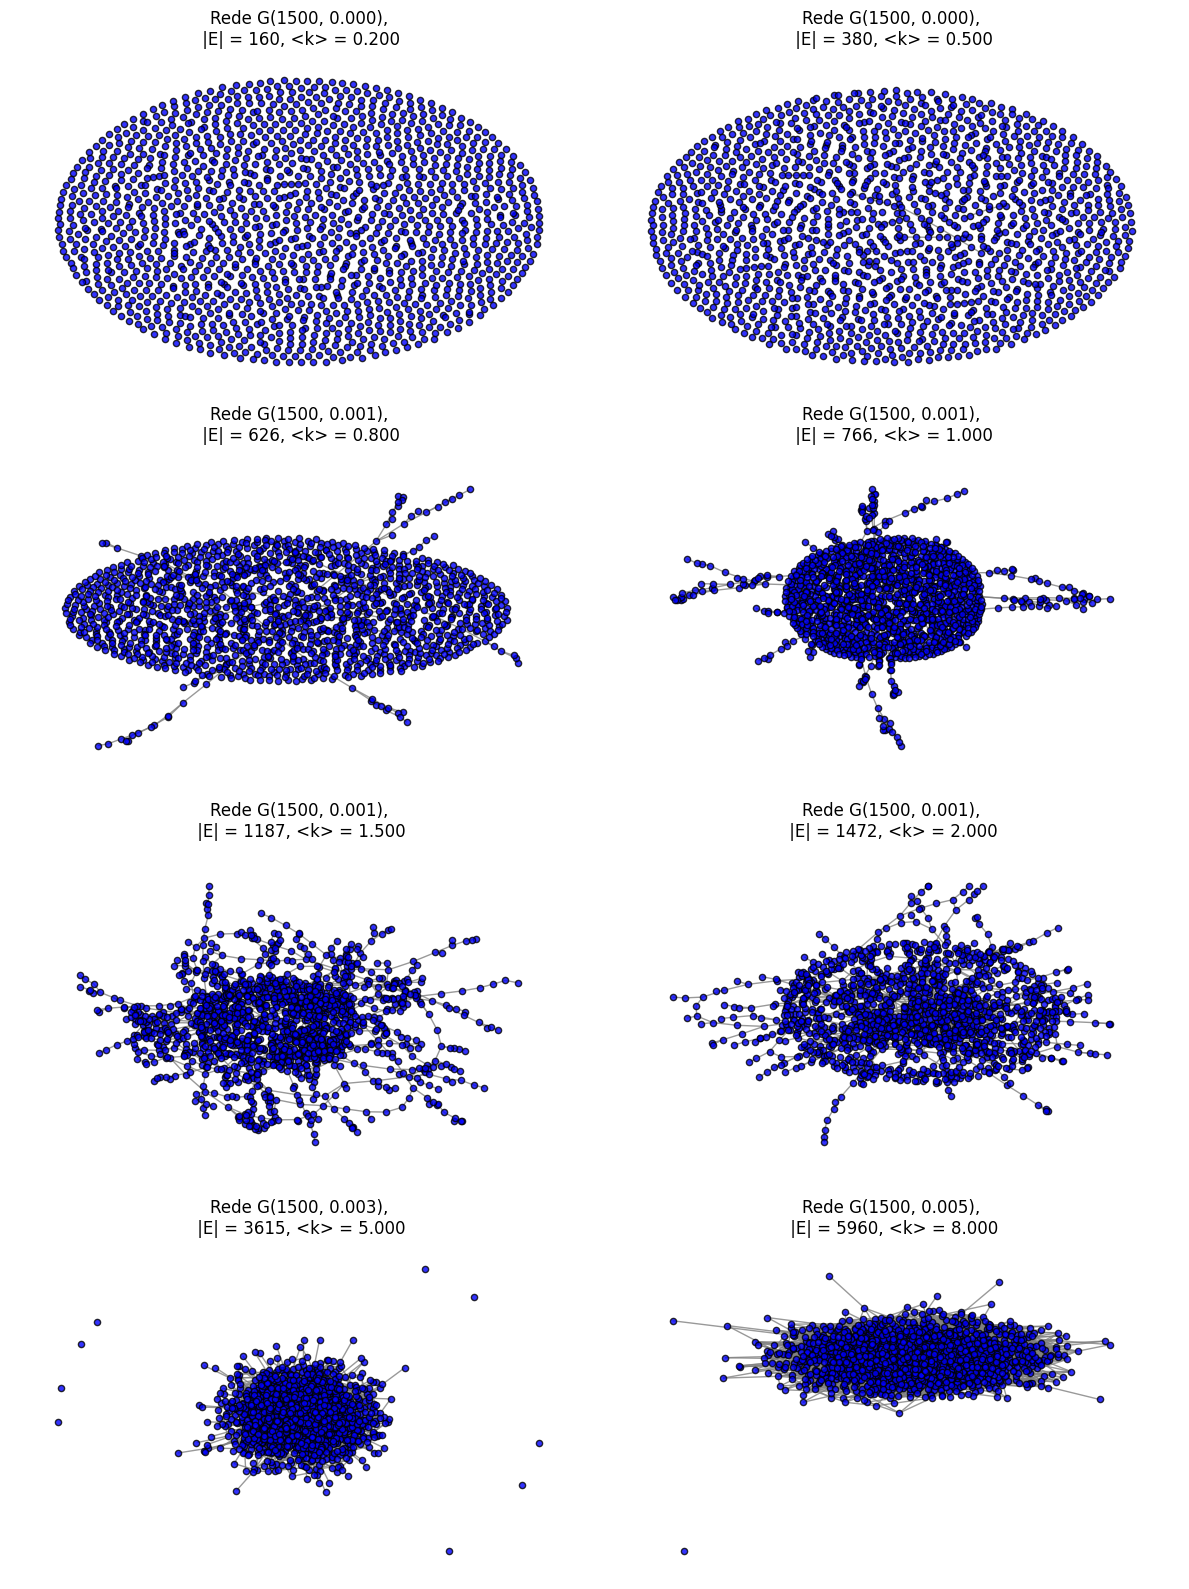

In [ ]:
fig, grid_axs = plt.subplots(4, 2, figsize=(12, 16))
axs = grid_axs.flatten()

for i in range(len(ps)):
    V, E = G(N, ps[i])
    graph = nx.Graph()
    graphs.append(graph)

    graph.add_nodes_from(V)
    graph.add_edges_from(E)

    pos = nx.spring_layout(graph)
    nx.draw(graph, pos, node_size=20, node_color="blue", edge_color="gray", edgecolors="black", alpha=0.8, ax=axs[i])

    axs[i].set_title(f'Rede G({N}, {ps[i]:.5f}),\n |E| = {len(E)}, <k> = {ks[i]:.2f}')
    axs[i].margins(0.1)

fig.tight_layout()

**Item b)** Para cada valor de ⟨k⟩, calcule o tamanho do maior componente conexo (como fração de N) e plote esse valor em função de ⟨k⟩. Você deve observar a transição de fase próxima de ⟨k⟩ = 1 discutida no Exercício 2.

Prob: 0.00013,	<K>: 0.20,	Arestas: 160,	Componentes: 1340,	Tamanho max componentes:    5
Prob: 0.00033,	<K>: 0.50,	Arestas: 380,	Componentes: 1120,	Tamanho max componentes:   17
Prob: 0.00053,	<K>: 0.80,	Arestas: 626,	Componentes:  874,	Tamanho max componentes:   42
Prob: 0.00067,	<K>: 1.00,	Arestas: 766,	Componentes:  735,	Tamanho max componentes:   82
Prob: 0.00100,	<K>: 1.50,	Arestas: 1187,	Componentes:  387,	Tamanho max componentes:  963
Prob: 0.00133,	<K>: 2.00,	Arestas: 1472,	Componentes:  250,	Tamanho max componentes: 1180
Prob: 0.00334,	<K>: 5.00,	Arestas: 3615,	Componentes:   10,	Tamanho max componentes: 1491
Prob: 0.00534,	<K>: 8.00,	Arestas: 5960,	Componentes:    2,	Tamanho max componentes: 1499


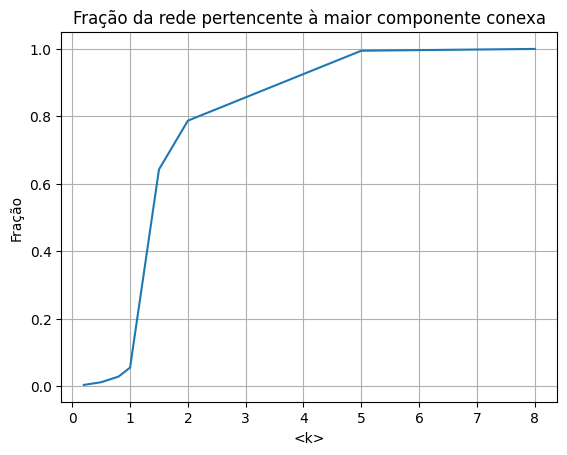

In [44]:
xs = []
ys = []

for p, k, g in zip(ps, ks, graphs):
    componentes = list(nx.connected_components(g))
    tamanho_max_componente = len(max(componentes, key=len))

    xs.append(k)
    ys.append(tamanho_max_componente/N)
    print(f"Prob: {p:.5f},\t<K>: {k:.2f},\tArestas: {g.number_of_edges()},\tComponentes: {len(componentes):4d},\tTamanho max componentes: {tamanho_max_componente:4d}")

plt.plot(xs, ys)
plt.ylabel('Fração')
plt.xlabel('<k>')
plt.grid(True)
plt.title('Fração da rede pertencente à maior componente conexa')
plt.show()

**Item c)** Fixando ⟨k⟩ = 8, gere redes com N crescente (por exemplo: 100, 300, 1000, 3000, 10000) e calcule o caminho médio (average shortest path length) dentro do maior componente de cada rede. Plote seu resultado contra a previsão teórica ⟨d⟩ ≈ ln(N)/ln(⟨k⟩) em função de N (uma escala logarítmica no eixo N ajuda a visualizar).

In [52]:
K = 8
Ns = [100, 300, 1000, 3000] # 10 mil é inviável no meu computador
xs_N = []
ys_avg = []
ys_esp = []

for n in Ns:
    xs_N.append(n)

    V, E = G(n, k / n)
    g = nx.Graph()

    g.add_edges_from(E)
    g.add_nodes_from(V)

    # caminhos em grafos não conexos geram problemas
    max_connected = max(nx.connected_components(g), key=len)
    g_sub = g.subgraph(max_connected)

    ys_avg.append(nx.average_shortest_path_length(g_sub))
    ys_esp.append(np.log(n) / np.log(k))

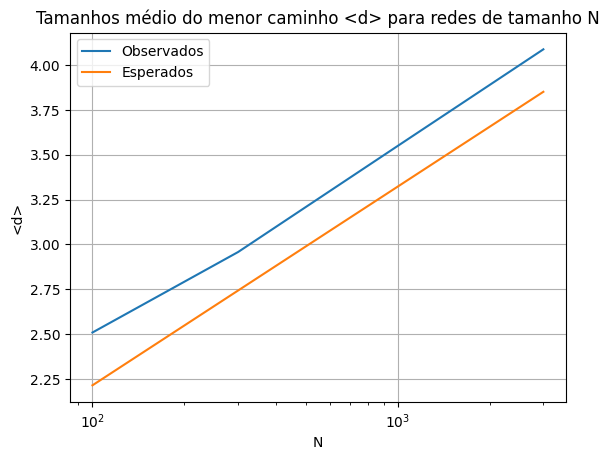

In [53]:
plt.plot(xs_N, ys_avg, label='Observados')
plt.plot(xs_N, ys_esp, label='Esperados')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('<d>')
plt.title('Tamanhos médio do menor caminho <d> para redes de tamanho N')
plt.legend()
plt.grid(True)
plt.show()

**Item d)** Ainda com ⟨k⟩ = 8 e N = 5000, plote o histograma da distribuição de grau da rede aleatória gerada e compare, no mesmo gráfico, com a distribuição de grau da rede de resultados da FIFA usada no Exercício 4. Comente: a rede aleatória produz "hubs" comparáveis aos observados na rede real? O que essa diferença sugere sobre os limites do modelo de Erdős–Rényi para representar redes do mundo real? (Você não precisa resolver esse problema agora — é uma reflexão que antecipa o próximo tópico do curso.)

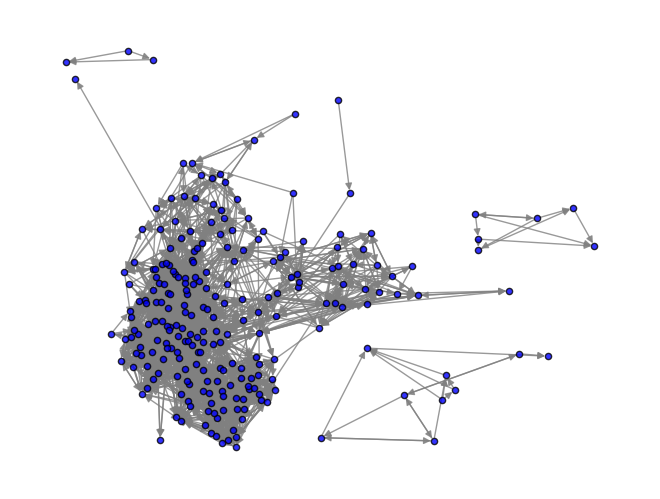

In [48]:
FIFA_EDGES_PATH = 'football_edges_filtered.csv'

edges_df = pd.read_csv(FIFA_EDGES_PATH)
fifa_graph = nx.from_pandas_edgelist(edges_df, source='source', target='target', edge_attr='weight', create_using=nx.DiGraph)

pos = nx.spring_layout(fifa_graph, k=0.3)
nx.draw(fifa_graph, pos, node_size=20, node_color="blue", edge_color="gray", edgecolors="black", alpha=0.8)

In [54]:
N = 5000
K = 8

V, E = G(N, K / N)
graph = nx.Graph()
graph.add_edges_from(E)
graph.add_nodes_from(V)

graus_gnp = [degree for _, degree in graph.degree()]
graus_fifa = [degree for _, degree in fifa_graph.degree()]

grau_max_gnp = max(graus_gnp)
grau_max_fifa = max(graus_fifa)

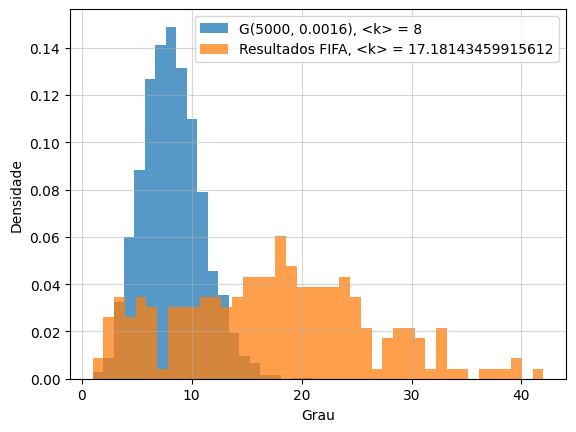

In [59]:
plt.hist(graus_gnp, bins=grau_max_gnp, alpha=0.75, density=True, label=f'G({N}, {K / N}), <k> = {K}')
plt.hist(graus_fifa, bins=grau_max_fifa, alpha=0.75, density=True, label=f'Resultados FIFA, <k> = {(2 * fifa_graph.number_of_edges()) / fifa_graph.number_of_nodes()}')

plt.xlabel('Grau')
plt.ylabel('Densidade')
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

Assim como visto em aula, redes aleatórias do modelo Erdos-Remyi possuem uma cauda mais leve que a de redes reais. Por causa disso, esse modelo não gera o mesmo número de hubs que o encontrado na rede da fifa, que tem grau médio/máximo maior (além de melhor distribuído), por exemplo. Além disso, de modo mais geral, esse fator cria uma limitação quanto à representatividade do modelo.

---

## Questão 04 -  Rede de Resultados da FIFA — Centralidade e PageRank Personalizado

A base de dados fornecida (arquivo .csv com colunas Source, Target, Weight) representa um grafo dirigido e ponderado: uma aresta de A para B significa que a seleção A perdeu para a seleção B; um empate gera uma aresta em cada direção; o peso reflete a importância da partida (por exemplo, uma final de Copa do Mundo pesa mais do que um amistoso).

**Item a)** Descreva a rede: quantos nós (seleções) e arestas (confrontos) ela tem? Ela é (fracamente/fortemente) conexa? Qual seleção tem o maior grau de entrada simples (contagem bruta de vitórias, sem ponderar)?

In [64]:
print(f'Número de nós (seleções): {fifa_graph.number_of_nodes()}')
print(f'Número de aresta (partidas): {fifa_graph.number_of_edges()}')
print(f'Fracamente conexa: {nx.is_weakly_connected(fifa_graph)}')
print(f'Fortemente conexa: {nx.is_strongly_connected(fifa_graph)}')

print(f'Seleções com maior grau de entrada:')
fifa_in_degrees = sorted(dict(fifa_graph.in_degree()).items(), key=(lambda x: -x[1]))
for s, d in fifa_in_degrees[:5]:
    print(f'- {s}: {d}')

Número de nós (seleções): 237
Número de aresta (partidas): 2036
Fracamente conexa: False
Fortemente conexa: False
Seleções com maior grau de entrada:
- Morocco: 32
- Canada: 25
- Mexico: 24
- England: 23
- Algeria: 23


**Item b)** Calcule a centralidade autovetor, a centralidade de Katz e o PageRank — todas ponderadas pelo peso da aresta — para todas as seleções. Monte uma tabela com o Top 10 de cada medida. As três concordam no topo do ranking? Onde discordam, e por quê? (Lembre-se: as três compartilham a mesma ideia recursiva — "importância flui de quem perde para quem vence" — mas diferem em como tratam atenuação e normalização; vale revisitar a relação Katz ↔ PageRank vista em aula.)

In [75]:
autovetor = nx.eigenvector_centrality(fifa_graph, weight='weight')
autovetor_sorted = sorted(autovetor.items(), key=(lambda x: -x[1]))

pagerk = nx.pagerank(fifa_graph, weight='weight')
pagerk_sorted = sorted(pagerk.items(), key=(lambda x: -x[1]))

A = nx.to_numpy_array(fifa_graph, weight='weight')
lambda_max = max(abs(np.linalg.eigvals(A)))
alpha_katz = 0.99 / lambda_max 
katz = nx.katz_centrality(fifa_graph, alpha=alpha_katz, beta=1.0, weight='weight', max_iter=2000)
katz_sorted = sorted(katz.items(), key=(lambda x: -x[1]))


df_centralidades = pd.DataFrame()
df_centralidades['Autovetor'] = autovetor_sorted
df_centralidades['Katz'] = katz_sorted
df_centralidades['PageRank'] = pagerk_sorted

df_centralidades.head(10)

,Autovetor,Katz,PageRank
0,"(Argentina, 0.29504432088552157)","(Argentina, 0.2924872275763129)","(Spain, 0.02542571374149392)"
1,"(Paraguay, 0.2852418209356692)","(Paraguay, 0.279912558553307)","(England, 0.020718596961566423)"
2,"(Spain, 0.2808284432279121)","(Spain, 0.279727295718291)","(France, 0.02000988676995273)"
3,"(Ecuador, 0.2549494147076663)","(Ecuador, 0.2506494960702258)","(Argentina, 0.01996050001716457)"
4,"(Brazil, 0.2355958743783901)","(Brazil, 0.2321236710554382)","(Paraguay, 0.01775431742540213)"
5,"(Colombia, 0.2190811699277495)","(Colombia, 0.21666690224471477)","(Portugal, 0.016560544289784526)"
6,"(France, 0.21591525012678872)","(France, 0.21602644027465415)","(Ecuador, 0.015038934518611737)"
7,"(Uruguay, 0.21063804610074272)","(Uruguay, 0.20707191213481038)","(Brazil, 0.014624176575136635)"
8,"(England, 0.1785947088414736)","(England, 0.18010954369192755)","(Netherlands, 0.014545157460215443)"
9,"(Mexico, 0.17272559886433503)","(Mexico, 0.17286036043027186)","(Morocco, 0.014342153429446202)"


**Resposta:** As medidas de centralidade por autovetor e por katz concordam quase totalmente entre si, mas o pagerank muda a ordem. Isso se dá devido ao fato desse último penalizar nós com saída grande, de forma que sua influência não seja totalmente repassada aos vizinhos, coisa que os dois primeiros não fazem.

**Item c)** Questão crítica. A distinção hub/autoridade do HITS foi pensada originalmente para a Web, onde uma página tende a ser predominantemente hub (uma lista de links) ou predominantemente autoridade (um conteúdo referenciado). Nesta rede de futebol, cada seleção desempenha os dois papéis ao mesmo tempo — perde às vezes, vence às vezes. Calcule ainda assim os escores de hub e de autoridade do HITS. Eles trazem alguma informação que o PageRank/eigenvector não trazem, ou a distinção hub/autoridade simplesmente colapsa nessa rede? Justifique com base nos resultados obtidos — não apenas na teoria.

In [79]:
fifa_hubs, fifa_autoridades = nx.hits(fifa_graph)
fifa_hubs_sorted = sorted(fifa_hubs.items(), key=(lambda x: -x[1]))
fifa_autoridades_sorted = sorted(fifa_autoridades.items(), key=(lambda x: -x[1]))

print('top 10 hubs:')
for s, _ in fifa_hubs_sorted[:10]:
    print(f'- {s}')

print()
print('top 10 autoridades:')
for s, _ in fifa_autoridades_sorted[:10]:
    print(f'- {s}')

top 10 hubs:
- Saudi Arabia
- Bolivia
- Uruguay
- Brazil
- Peru
- Chile
- Jordan
- Venezuela
- Paraguay
- Iraq

top 10 autoridades:
- Argentina
- Morocco
- Spain
- Colombia
- Paraguay
- Algeria
- Ecuador
- Brazil
- Uruguay
- Mexico


**Resposta:** Os resultados de HITS mostram países que não tinham aparecido nas medidas anteriores, como Arábia Saudita, Bolívia e Venezuala. Esses são times que perdem frequentemente para times fortes, logo são valorizados pelo HITS, pois apontam para nós autoritários, possuindo uma relação positiva na lógica de hubs <-> autoridades valorizada pelo algoritmo.

**Item d)** PageRank Personalizado. Calcule o PageRank personalizado em duas variantes e compare ambas com o Top 10 do PageRank global do item (b):

**Item d.i)** Escolha uma seleção X (por exemplo, o Brasil) e calcule o PageRank personalizado com o vetor de teletransporte concentrado 100% em X (parâmetro personalization do NetworkX, ou implementação própria via iteração de potência).

In [ ]:
alvo = 'Brazil' 
personalizado_br = {node: 0.0 for node in fifa_graph.nodes()}
personalizado_br[alvo] = 1.0

pagerk_br = nx.pagerank(fifa_graph, weight='weight', personalization=personalizado_br)
pagerk_br_sorted = sorted(pagerk_br.items(), key=(lambda x: -x[1]))

print('Top 10 Page Rank personalizado:')
for selecao, score in pagerk_br_sorted[:10]:
    print(f'- {selecao}: {score}')

Top 10 Page Rank personalizado:
- Brazil: 0.17591163439630933
- Paraguay: 0.047850074485102534
- Argentina: 0.041358823794557326
- Ecuador: 0.03534228260184309
- Spain: 0.031033439646753903
- Bolivia: 0.03019254420631766
- France: 0.030122400213910307
- Japan: 0.027961669946266615
- Norway: 0.027081473444002583
- Uruguay: 0.026761874218198378


**Item d.ii)** Escolha agora uma confederação inteira (por exemplo, a CONMEBOL ou a CONCACAF) e calcule o PageRank personalizado com o vetor de teletransporte distribuído entre todas as seleções dessa confederação (você decide se a distribuição será uniforme entre elas ou ponderada por algum critério — justifique sua escolha).

In [84]:
conmebol = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Ecuador", "Paraguay", "Peru", "Uruguay", "Venezuela"]
personalizado_conf = {node: 0.0 for node in fifa_graph.nodes()}

for selecao in conmebol:
    personalizado_conf[selecao] = 1.0 / len(conmebol)

pagerk_conmebol = nx.pagerank(fifa_graph, weight="weight", personalization=personalizado_conf)
pagerk_conmebol_sorted = sorted(pagerk_conmebol.items(), key=(lambda x: -x[1]))

print('Top 10 Page Rank personalizado:')
for selecao, score in pagerk_conmebol_sorted[:10]:
    print(f'- {selecao}: {score}')

Top 10 Page Rank personalizado:
- Paraguay: 0.06161858767610455
- Ecuador: 0.05484124382037632
- Argentina: 0.05188230115360594
- Brazil: 0.04961590484331456
- Colombia: 0.046102526296645754
- Uruguay: 0.045474772114652
- Bolivia: 0.03940526512448257
- Venezuela: 0.03917978569459935
- Spain: 0.03468601905536356
- Peru: 0.0311933241647624


Para as duas variantes, discuta:

Quais seleções aparecem no ranking personalizado que não apareciam no ranking global? O que essa diferença captura, em termos de "ameaça específica" (no caso i) ou "relevância regional" (no caso ii), que o ranking global — voltado à seleção/região mais forte do mundo em geral — não captura?

Compare os dois rankings personalizados entre si (item i vs. item ii). O ranking da confederação inteira (ii) se aproxima mais do ranking individual (i) ou do ranking global (b)? Sob qual condição você esperaria que a personalização por confederação ficasse praticamente indistinguível do PageRank global? (Dica: pense no que acontece quando o conjunto de teletransporte cresce até incluir todas as seleções.)

Esse é o mesmo princípio por trás de sistemas de recomendação personalizados no mundo real — por exemplo, o antigo algoritmo "Who to Follow" do Twitter, ou o sistema Pixie do Pinterest: a importância de um nó não é absoluta, é relativa a um ponto de partida, que pode ser tanto um indivíduo quanto um grupo/interesse inteiro (essa ideia mais geral é conhecida como PageRank tópico-sensível, de Haveliwala, 2002)

**Resposta:** Personalizando o algoritmo podemos ver um maior destaque às dinâmicas locais dos jogos. Com apenas o Brasil, rivais fortes sobem muito em rank, enquanto seleções globalmente fortes, mas que não são tão presentes, caem. Similarmente, restringindo à CONMEBOL vemos essa dinâmica se repetindo, com times fortes da confederação sendo priorizados. Esse processo permite, em certo sentido, mudar a lente com a qual se enxerga as relações na rede e focar em grupos específicos.

**Item e)** Limitações. Aponte pelo menos duas limitações dessa rede/abordagem como medida de "força" de uma seleção (por exemplo: ausência de ponderação por recência dos jogos, efeito de mando de campo não considerado, margem de vitória/número de gols ignorado, viés de calendário — seleções que jogam mais partidas contra adversários fracos ou fortes). Escolha uma dessas limitações e proponha, em termos concretos, como você tentaria corrigi-la nesse mesmo arcabouço de centralidade em grafos.

**Resposta:** De modo geral, podemos dizer facilmente que apenas as relações de vitória/derrota em cada jogo não são suficente para descrever um time por inteiro. Podemos impedir que partidas antigas tenham um impacto tão grande quanto jogos recentes adicionando um decaimento temporal para os resultados observados. Podemos tentar lidar com a margem de vitória ponderando por uma razão de gols em uma partida. Entretanto, essas ideias precisam ser testadas e ajustadas, não é possível dizer previamente o que funciona.